**Name:** Akhilesh Kombe                       
**Division:** A &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **Batch:** A3    
**PRN:** 202401040244                         
**Roll No.:** TY-057                                     


# ASSIGNMENT NO. 2
## Feature Engineering Using Python

**Course:** Artificial Intelligence and Machine Learning  
**Course Code:** 2304322T  
**Assignment Question:** To implement techniques of Feature Engineering to transform raw data into informative features.

### Aim
To understand and implement various Feature Engineering techniques using Python, including data cleaning, handling missing values, statistical analysis, feature creation, categorical encoding, feature scaling, feature selection and data visualization.

### Objective
1. To understand the importance of Feature Engineering.
2. To analyze raw datasets using statistical methods.
3. To identify and handle missing values and duplicate records.
4. To create meaningful features from existing data.
5. To apply encoding and scaling techniques.
6. To identify important features using statistical methods.
7. To visualize and interpret the processed data.

## Introduction

Feature Engineering is the process of transforming raw data into meaningful and informative features that improve the performance of machine learning algorithms.

It involves selecting, modifying, combining and creating features from existing datasets.

### Importance of Feature Engineering

- Improves the quality of input data.
- Handles missing and inconsistent values.
- Helps identify important patterns.
- Improves machine learning model performance.
- Reduces unnecessary information.
- Makes data suitable for machine learning algorithms.

### Techniques Used

1. Missing Value Imputation
2. Duplicate Removal
3. Outlier Detection
4. Feature Creation
5. Categorical Encoding
6. Feature Scaling
7. Feature Selection
8. Data Visualization

### Dataset Used

The Titanic dataset is used in this assignment. It contains passenger information such as age, gender, passenger class, ticket fare, family details and survival status.

The target variable is `survived`, which indicates whether a passenger survived or not.

In [25]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [26]:
# Loading the Titanic dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first five records
df.head()

Dataset loaded successfully!
Dataset Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [27]:
# Dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nFirst 10 Records:")
display(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN



First 10 Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False



Dataset Shape:
(891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [28]:
# Checking missing values

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_report.sort_values(
    by='Missing Percentage',
    ascending=False
))

# Checking duplicate records
print("Duplicate Records:", df.duplicated().sum())

,Missing Values,Missing Percentage
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


Duplicate Records: 107


## Statistical Analysis

Statistical analysis helps us understand the distribution, central tendency and relationships between different features.

### 1. Mean

Mean is the average of all numerical observations.

Formula:

Mean = Sum of all observations / Number of observations

### 2. Median

Median is the middle value of an ordered dataset. It is useful when the dataset contains outliers.

### 3. Standard Deviation

Standard deviation measures how much the values differ from their mean.

### 4. Correlation

Correlation measures the relationship between two numerical variables. Its value ranges from -1 to +1.

- +1: Strong positive correlation.
- -1: Strong negative correlation.
- 0: No linear correlation.

### 5. Variance

Variance measures the spread of data around its mean.

These statistical concepts help in understanding data quality and selecting suitable preprocessing techniques.

In [29]:
# Statistical analysis of numerical features

numerical_columns = df.select_dtypes(
    include=np.number
).columns

statistics = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Mode': df[numerical_columns].mode().iloc[0],
    'Variance': df[numerical_columns].var(),
    'Standard Deviation': df[numerical_columns].std(),
    'Minimum': df[numerical_columns].min(),
    'Maximum': df[numerical_columns].max()
})

display(statistics.round(2))

,Mean,Median,Mode,Variance,Standard Deviation,Minimum,Maximum
survived,0.38,0.00,0.00,0.24,0.49,0.00,1.00
pclass,2.31,3.00,3.00,0.70,0.84,1.00,3.00
age,29.70,28.00,24.00,211.02,14.53,0.42,80.00
sibsp,0.52,0.00,0.00,1.22,1.10,0.00,8.00
parch,0.38,0.00,0.00,0.65,0.81,0.00,6.00
fare,32.20,14.45,8.05,2469.44,49.69,0.00,512.33


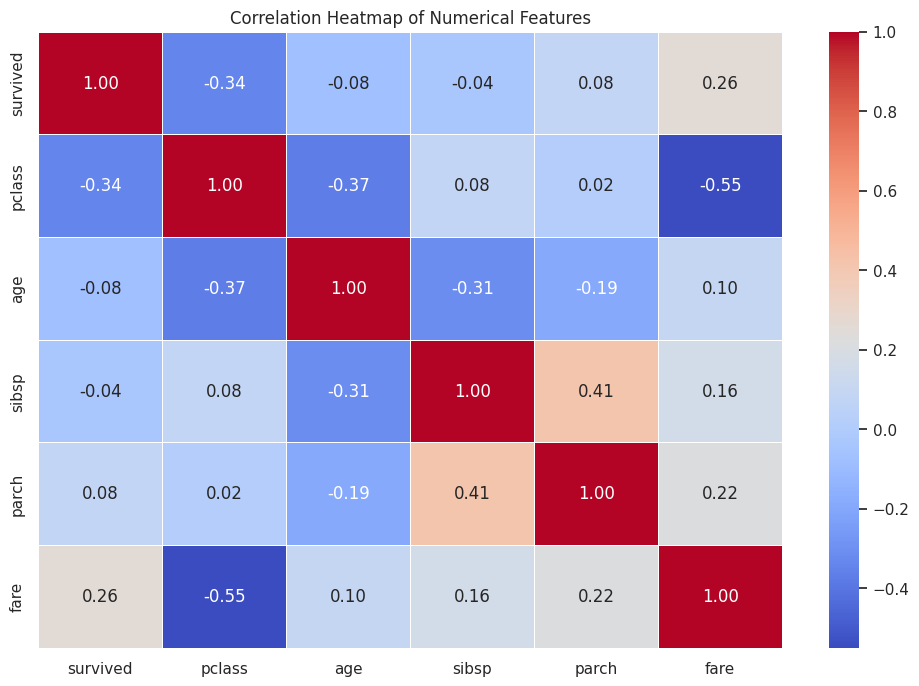

In [30]:
# Correlation analysis

correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

## Data Cleaning and Preparation

Data preparation is an important step in Feature Engineering.

The following operations are performed:

1. Remove duplicate records.
2. Identify missing values.
3. Handle missing numerical values using median imputation.
4. Handle missing categorical values using mode imputation.
5. Identify outliers using the Interquartile Range (IQR) method.

### Interquartile Range (IQR)

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 * IQR

Upper Bound = Q3 + 1.5 * IQR

Values outside these limits are considered potential outliers.

Median imputation is useful for numerical data because it is less affected by extreme values.

In [31]:
# Removing duplicate records

df_clean = df.drop_duplicates().copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

# Checking missing values after duplicate removal

print("\nMissing Values:")
print(df_clean.isnull().sum())

# IQR outlier detection for Age and Fare

for column in ['age', 'fare']:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    print(f"\n{column.upper()} OUTLIER ANALYSIS")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Potential Outliers:", len(outliers))

Original Dataset Shape: (891, 15)
Cleaned Dataset Shape: (784, 15)

Missing Values:
survived         0
pclass           0
sex              0
age            106
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           582
embark_town      2
alive            0
alone            0
dtype: int64

AGE OUTLIER ANALYSIS
Q1: 20.0
Q3: 39.0
IQR: 19.0
Lower Bound: -8.5
Upper Bound: 67.5
Number of Potential Outliers: 7

FARE OUTLIER ANALYSIS
Q1: 8.05
Q3: 34.10935
IQR: 26.05935
Lower Bound: -31.039025
Upper Bound: 73.198375
Number of Potential Outliers: 102


In [32]:
# Creating a copy of cleaned dataset

df_fe = df_clean.copy()

# 1. Creating Family Size
df_fe['family_size'] = (
    df_fe['sibsp'] + df_fe['parch'] + 1
)

# 2. Creating Is Alone feature
df_fe['is_alone'] = (
    df_fe['family_size'] == 1
).astype(int)

# 3. Creating Fare Per Person
df_fe['fare_per_person'] = (
    df_fe['fare'] / df_fe['family_size']
)

# 4. Extracting Title from Passenger Name
df_fe['title'] = (
    df_fe['who'].str.title()
)

# 5. Creating Age Group
df_fe['age_group'] = pd.cut(
    df_fe['age'],
    bins=[0, 18, 60, np.inf],
    labels=['Child', 'Adult', 'Senior'],
    right=False
)

# Display engineered features
engineered_columns = [
    'age', 'sibsp', 'parch', 'family_size',
    'is_alone', 'fare', 'fare_per_person',
    'who', 'title', 'age_group'
]

display(df_fe[engineered_columns].head(15))

print("Feature Engineering Completed Successfully!")

,age,sibsp,parch,family_size,is_alone,fare,fare_per_person,who,title,age_group
0,22.0,1,0,2,0,7.2500,3.625000,man,Man,Adult
1,38.0,1,0,2,0,71.2833,35.641650,woman,Woman,Adult
2,26.0,0,0,1,1,7.9250,7.925000,woman,Woman,Adult
3,35.0,1,0,2,0,53.1000,26.550000,woman,Woman,Adult
4,35.0,0,0,1,1,8.0500,8.050000,man,Man,Adult
5,NaN,0,0,1,1,8.4583,8.458300,man,Man,NaN
6,54.0,0,0,1,1,51.8625,51.862500,man,Man,Adult
7,2.0,3,1,5,0,21.0750,4.215000,child,Child,Child
8,27.0,0,2,3,0,11.1333,3.711100,woman,Woman,Adult
9,14.0,1,0,2,0,30.0708,15.035400,child,Child,Child


Feature Engineering Completed Successfully!


In [33]:
# Fare category creation using quantile-based binning

df_fe['fare_category'] = pd.qcut(
    df_fe['fare'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High'],
    duplicates='drop'
)

print("Fare Category Distribution:")
display(df_fe['fare_category'].value_counts())

# Display all new features
display(df_fe.head())

Fare Category Distribution:


,count
fare_category,
Low,214
Very High,196
High,195
Medium,179


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,family_size,is_alone,fare_per_person,title,age_group,fare_category
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,2,0,3.62500,Man,Adult,Low
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,2,0,35.64165,Woman,Adult,Very High
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,1,1,7.92500,Woman,Adult,Low
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,2,0,26.55000,Woman,Adult,Very High
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1,1,8.05000,Man,Adult,Low


In [34]:
# Selecting useful features and target variable

selected_features = [
    'pclass',
    'sex',
    'age',
    'sibsp',
    'parch',
    'fare',
    'embarked',
    'family_size',
    'is_alone',
    'fare_per_person',
    'title',
    'age_group',
    'fare_category'
]

X = df_fe[selected_features].copy()
y = df_fe['survived'].copy()

# Separate numerical and categorical features

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (627, 13)
Testing Data Shape: (157, 13)


In [35]:
# Numerical preprocessing

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combining both pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

# Fit on training data and transform both datasets

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed Successfully!")

print("Processed Training Shape:",
      X_train_processed.shape)

print("Processed Testing Shape:",
      X_test_processed.shape)

Preprocessing Completed Successfully!
Processed Training Shape: (627, 23)
Processed Testing Shape: (157, 23)


In [36]:
# Get transformed feature names

feature_names = preprocessor.get_feature_names_out()

# Calculate Mutual Information scores

mi_scores = mutual_info_classif(
    X_train_processed,
    y_train,
    random_state=42
)

# Create feature importance table

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mutual Information Score': mi_scores
})

feature_importance = feature_importance.sort_values(
    by='Mutual Information Score',
    ascending=False
)

display(feature_importance.head(15))

,Feature,Mutual Information Score
8,cat__sex_female,0.130089
7,num__fare_per_person,0.119478
14,cat__title_Man,0.098922
9,cat__sex_male,0.098402
4,num__fare,0.085777
15,cat__title_Woman,0.085229
22,cat__fare_category_Very High,0.073165
5,num__family_size,0.067037
10,cat__embarked_C,0.042867
20,cat__fare_category_Low,0.041376


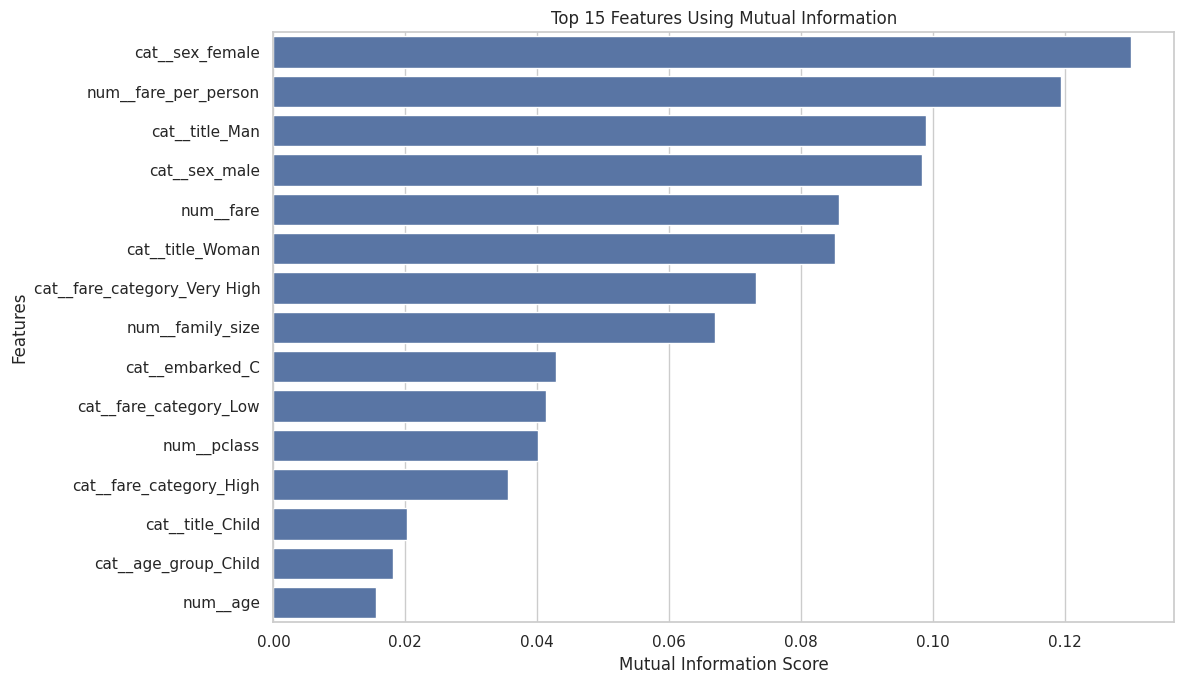

In [37]:
# Visualizing top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x='Mutual Information Score',
    y='Feature'
)

plt.title("Top 15 Features Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

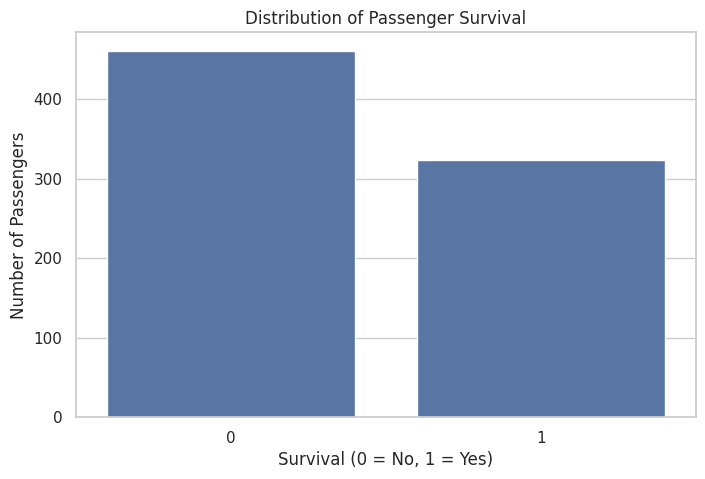

In [38]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_fe,
    x='survived'
)

plt.title("Distribution of Passenger Survival")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

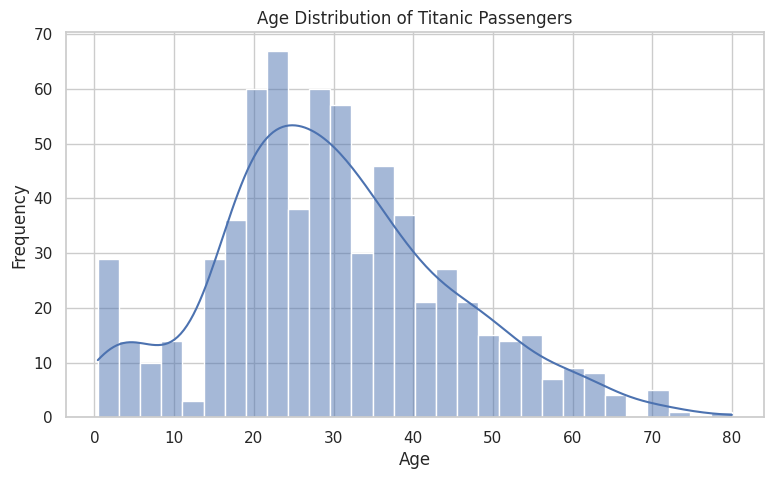

In [39]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_fe,
    x='age',
    kde=True,
    bins=30
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

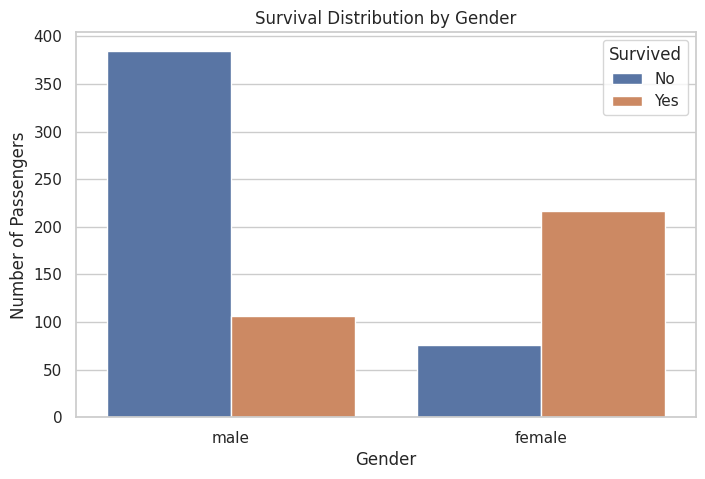

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_fe,
    x='sex',
    hue='survived'
)

plt.title("Survival Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survived",
    labels=["No", "Yes"]
)

plt.show()

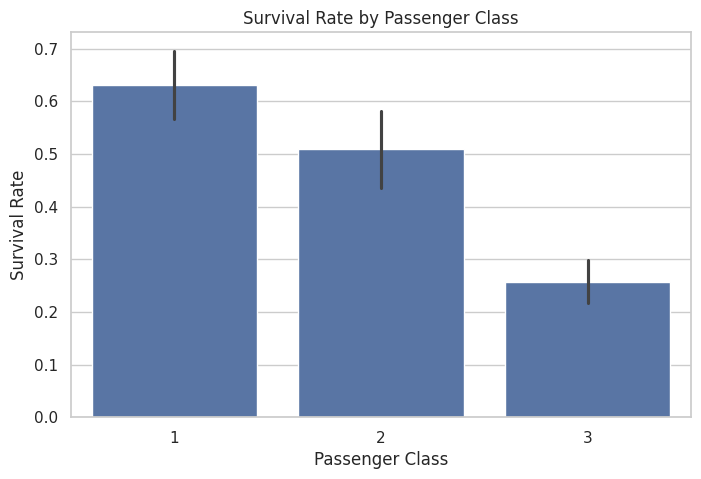

In [41]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_fe,
    x='pclass',
    y='survived'
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

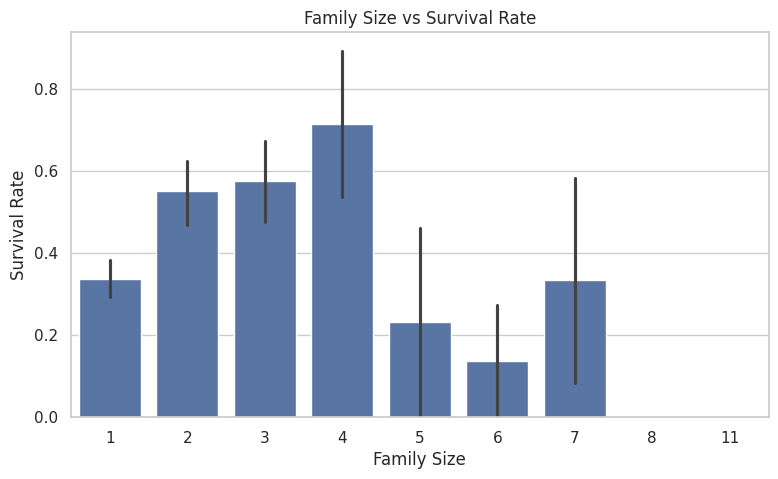

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_fe,
    x='family_size',
    y='survived'
)

plt.title("Family Size vs Survival Rate")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

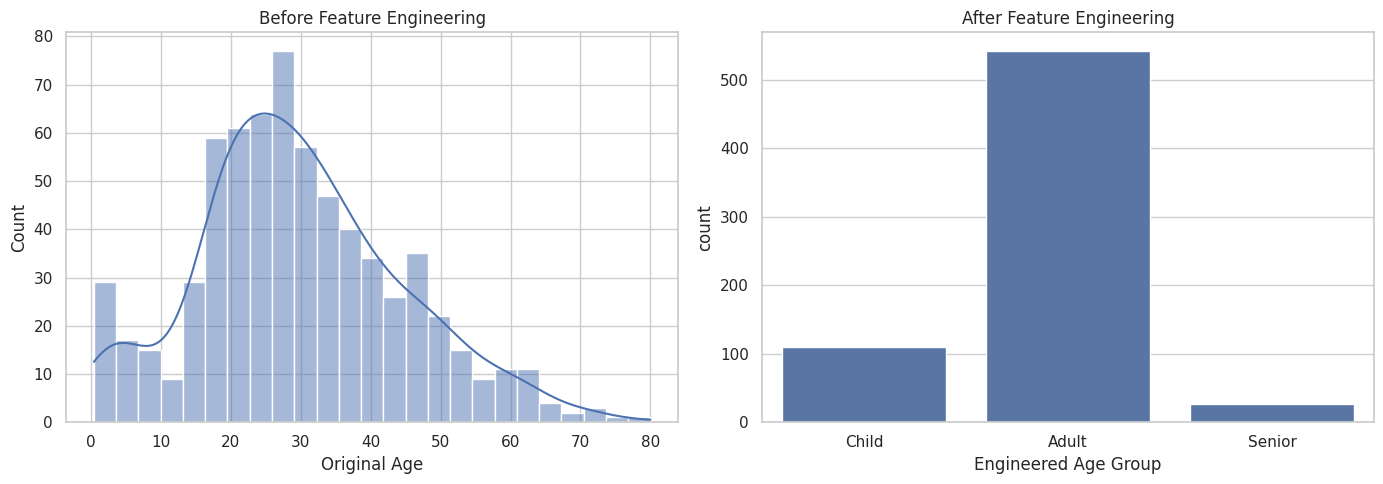

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before Feature Engineering
sns.histplot(
    data=df_clean,
    x='age',
    bins=25,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Before Feature Engineering")
axes[0].set_xlabel("Original Age")

# After Feature Engineering
sns.countplot(
    data=df_fe,
    x='age_group',
    ax=axes[1]
)

axes[1].set_title("After Feature Engineering")
axes[1].set_xlabel("Engineered Age Group")

plt.tight_layout()
plt.show()

In [44]:
# Creating Random Forest Classifier

model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Training the model

model.fit(X_train, y_train)

# Predictions

y_pred = model.predict(X_test)

# Model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Evaluation Results
------------------------
Accuracy: 82.17 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85        92
           1       0.80      0.75      0.78        65

    accuracy                           0.82       157
   macro avg       0.82      0.81      0.81       157
weighted avg       0.82      0.82      0.82       157



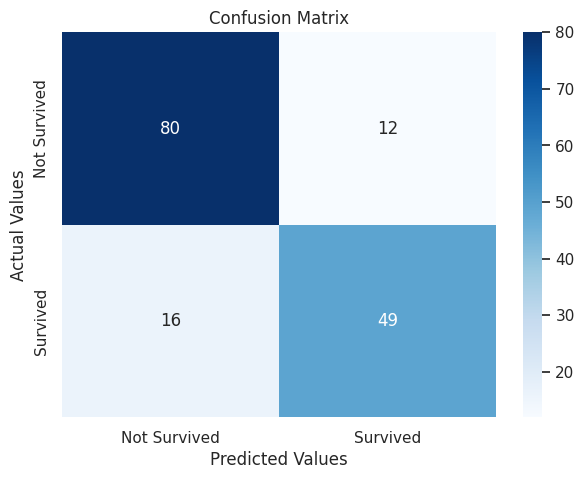

In [45]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

# Results and Conclusion

## Results

The Feature Engineering assignment was successfully implemented using Python in Google Colab.

The following operations were performed:

1. Loaded and explored the Titanic dataset.
2. Analyzed statistical properties such as mean, median, variance and standard deviation.
3. Identified missing values and duplicate records.
4. Performed outlier detection using the IQR method.
5. Created new features such as Family Size, Is Alone, Fare Per Person, Title and Age Group.
6. Applied median and mode imputation.
7. Applied One-Hot Encoding to categorical features.
8. Applied Standard Scaling to numerical features.
9. Selected important features using Mutual Information.
10. Created visualizations to understand data distribution and relationships.
11. Evaluated the processed dataset using a Random Forest classifier.

## Conclusion

Feature Engineering is an important step in the machine learning process because it transforms raw data into meaningful and useful information.

In this assignment, different Feature Engineering techniques were implemented using Python libraries such as Pandas, NumPy, Matplotlib and Scikit-learn.

The assignment demonstrated how missing values, duplicate records, categorical variables and numerical features can be processed to improve data quality.

New features were created from existing information, and statistical techniques were used to identify important features.

Finally, data visualization and machine learning evaluation were performed to understand the usefulness of the engineered features.

Thus, the objective of implementing Feature Engineering techniques to transform raw data into informative features was successfully achieved.